# Manipulation de données et visualisations

Date : 3 novembre 2026

Enseignant : Lazar van Berchem

# 2. Premières manipulations

## 2.1 Bibliothèques

L'import des bibliothèques se fait toujours au début du code, ce qui permet aux autres utilisateurs de savoir dès le début s'il y a des packages spéciaux à installer.

In [1]:
import pandas as pd

## 2.2 Importation des données

In [2]:
df = pd.read_csv("surrealisme.csv", sep=';')
df

,vente,maison,provenance,date_vente,date_creation,nom_oeuvre,nom_artiste,date_naissance_artiste,date_mort_artiste,matiere,...,prix,monnaie,dim_hauteur_cm,dim_largeur_cm,dim_epaisseur_cm,détails,expositions,matiere_corrigée,genre_m,prix_euro
0,Surrealism 18 oct,Sothebys,"Gardner Cowles, New York\n\nChristie's, New Yo...",18/10/2024,1945.0,Other answers,Kay Sage,1898.0,1963.0,huile sur toile,...,1020000.0,euros,40.5,33.0,NaN,signé Kay Sage et daté '45 (en bas à gauche); ...,NaN,peinture à l'huile,0,1020000.0
1,Surrealism 18 oct,Sothebys,"Albert Skira, Geneva (acquis directement auprè...",18/10/2024,1937.0,Minotaure (projet de couverture),Rene Magritte,1898.0,1967.0,gouache sur papier,...,1320000.0,euros,31.8,24.7,NaN,signé Magritte (en bas à droite),"Genève, Musée Rath et Paris, Musée d'Art Moder...",peinture à l'eau,1,1320000.0
2,Surrealism 18 oct,Sothebys,"Albert Skira, Geneva (acquis directement auprè...",18/10/2024,1939.0,Minotaure (Projet de couverture intérieure),Diego Rivera,1886.0,1957.0,gouache et crayon sur papier,...,102000.0,euros,36.5,54.5,NaN,signé Diego Rivera (en bas à droite). Nous rem...,"Geneva, Musée Rath and Paris, Musée d'Art Mode...",peinture à l'eau,1,102000.0
3,Surrealism 18 oct,Sothebys,"Albert Skira, Geneva (acquis directement auprè...",18/10/2024,1939.0,Minotaure (Projet de couverture intérieure),Andre Masson,1896.0,1987.0,gouache sur papier,...,60000.0,euros,32.0,58.0,NaN,signé andré Masson (en bas au centre),"Geneva, Musée Rath and Paris, Musée d'Art Mode...",peinture à l'eau,1,60000.0
4,Surrealism 18 oct,Sothebys,"Jacques Kaplan, New York (acquis directement a...",18/10/2024,1939.0,Personnage (femme assise),Man Ray,1890.0,1976.0,huile sur toile,...,1710000.0,euros,92.2,78.2,NaN,Signé Man Ray et daté 1939. Andrew Strauss et ...,"Princeton, University Art Museum, Man Ray, Dra...",peinture à l'huile,1,1710000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
488,Surrealism\nBeyond Reality,Bonhams,The artist's studio.\nJean L'Amouroux Collecti...,15/11/2023,1960.0,Sans titre (Femme avec un chat),Leonor Fini,1907.0,1996.0,pen and India ink on paper,...,3840.0,dollars,31.0,24.0,NaN,signed 'Leonor Fini' (lower right),,dessin,0,3840.0
489,Surrealism\nBeyond Reality,Bonhams,"Galerie Bonnier, Lausanne, no. A166, by 1961.\...",15/11/2023,1960.0,Dans l'herbe,Andre Masson,1896.0,1987.0,oil on canvas,...,32000.0,dollars,60.0,73.0,NaN,signed 'André Masson' (lower right),"Turku, Turun Taidemuseo Abo Konstmuseum, Masso...",peinture à l'huile,1,32000.0
490,Surrealism\nBeyond Reality,Bonhams,"Galeria Juan Martin, Mexico City.\nIturralde G...",15/11/2023,1967.0,Derecho de propiedad,Francisco Corzas,1936.0,1983.0,oil on canvas,...,48640.0,dollars,204.0,168.0,NaN,signed and dated 'Francisco Corzas 67'' (lower...,"New York, Center for Inter-American Relations,...",peinture à l'huile,1,48640.0
491,Surrealism\nBeyond Reality,Bonhams,"Gary Nader Fine Art, Miami.\nAcquired from the...",15/11/2023,1991.0,Paisaje cósmico,Rafael Soriano,1920.0,2015.0,oil on canvas,...,19200.0,dollars,61.0,50.0,NaN,signed 'Soriano' (lower left),NaN,peinture à l'huile,1,19200.0


## 2.3 Manipulations sur une colonne

L'idée est toujours la même : on écrit une fonction prenant en entrée ce que l'on s'attend à trouver dans une case d'une colonne particulière. Ensuite on utilise la strcuture suivante:

`df['le_nom_de_la_nouvelle_colonne'] = df['le_nom_de_la_colonne_modifiée'].apply(le_nom_de_la_fonction)`

In [3]:
def is_magritte(nom):
    if nom == "Rene Magritte":
        return 1
    else:
        return 0

print(is_magritte('Rene Magritte'))
print(is_magritte('Leonor Fini'))

df['is_magritte'] = df['nom_artiste'].apply(is_magritte)

1
0


In [4]:
# cette fonction permet d'afficher le nombre d'items par catégorie pour une colonne
df['is_magritte'].value_counts()

is_magritte
0    455
1     38
Name: count, dtype: int64

Exercice : écrivez une fonction permettant de créer une nouvelle colonne binaire (0/1) pour savoir trouver les oeuvres ayant été produites avant la parution du *Manifeste du surréalisme*.

In [5]:
def avant_manifeste(annee):
    if annee < 1924:
        return 1
    else:
        return 0

df["avant_manifeste"] = df["date_creation"].apply(avant_manifeste)

Exercice : écrivez une fonction permettant de créer une nouvelle colonne binaire pour savoir si l'oeuvre a été vendue l'année-anniversaire (2024).

Indice : n'hésitez pas à transformer chaque date en objet manipulable par pandas avec `pd.to_datetime(date)`. Dès lors vous pourrez extraire le jour avec `date.day`, le mois avec `date.month` ou encore l'année avec `date.year`.

In [6]:
def annee_anniversaire(date):
    date = pd.to_datetime(date)
    if date.year == 2024:
        return 1
    else:
        return 0

df["annee_anniversaire"] = df["date_vente"].apply(annee_anniversaire)

C:\Users\lvber\AppData\Local\Temp\ipykernel_15516\857268417.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  date = pd.to_datetime(date)


Exercice : écrivez une fonction permettant de créer une nouvelle colonne binaire pour savoir si l'oeuvre a été exposée.

In [7]:
def a_ete_exposee(exposition):
    if pd.isna(exposition):
        return 0
    else:
        return 1

df["a_ete_exposee"] = df["expositions"].apply(a_ete_exposee)

In [8]:
df["a_ete_exposee"].value_counts()

a_ete_exposee
0    289
1    204
Name: count, dtype: int64

Exercice : écrivez une fonction permettant de créer une nouvelle colonne binaire pour savoir si l'oeuvre est signée.

In [9]:
def est_signee(details):
    if pd.isna(details):
        return 0
    elif "sign" in details:
        return 1
    else:
        return 0

df["est_signee"] = df["détails"].apply(est_signee)

## 2.4 Manipulations sur plusieurs colonnes

Ici la structure change un peu, la fonction `apply()` s'applique désormais sur l'ensemble des cases, ligne par ligne (axis = 1).

In [10]:
def age_artiste(ligne):
    date_creation = ligne['date_creation']
    date_naissance = ligne['date_naissance_artiste']

    return date_creation - date_naissance

df['age_artiste'] = df.apply(age_artiste, axis=1)

Exercice : écrivez une fonction permettant de créer une nouvelle colonne pour savoir si l'oeuvre s'est vendue :
- 0 : en dessous de l'estimation,
- 1 : dans l'estimation,
- 2 : au-dessus de l'estimation.

Attention : faites attention aux Nan.

In [11]:
def comparaison_estimation(ligne):
    prix = ligne['prix']
    estimation_basse = ligne['estimation_basse']
    estimation_haute = ligne['estimation_haute']

    if pd.isna(prix) or pd.isna(estimation_basse) or pd.isna(estimation_haute):
        return pd.NA
    elif prix < estimation_basse:
        return 0
    elif prix <= estimation_haute:
        return 1
    else:
        return 2

df['vente_vs_estimation'] = df.apply(comparaison_estimation, axis=1)

Exercice : écrivez une fonction permettant de créer une nouvelle colonne pour calculer l'aire d'une oeuvre.

In [12]:
def aire(ligne):
    hauteur = ligne['dim_hauteur_cm']
    largeur = ligne['dim_largeur_cm']

    if not pd.isna(hauteur) and not pd.isna(largeur):
        return hauteur * largeur
    else:
        return pd.NA

df['aire'] = df.apply(aire, axis=1)

# 3. Introduction aux visualisations

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

## 3.1 Les distributions

Pour une variable catégorielle :

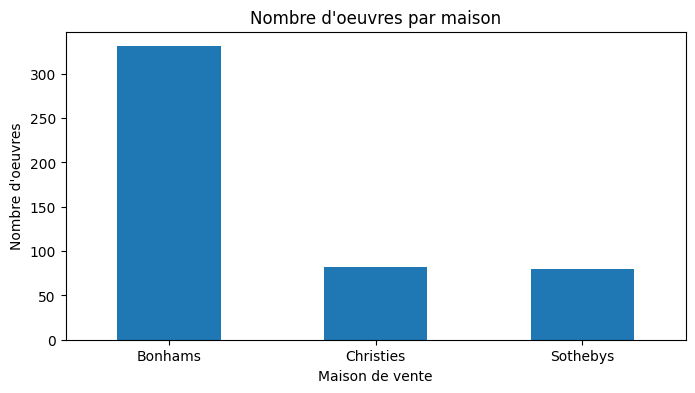

In [26]:
plt.figure(figsize=(8, 4))

df['maison'].value_counts().plot(kind='bar')

plt.xlabel("Maison de vente")
plt.ylabel("Nombre d'oeuvres")
plt.title("Nombre d'oeuvres par maison")

plt.xticks(rotation=0)
plt.show()

Pour une variable continue :

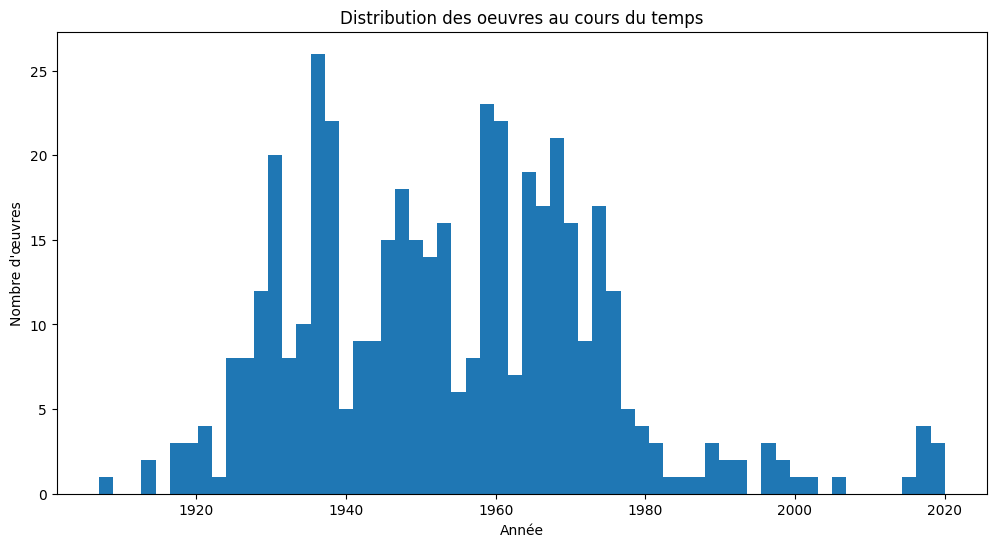

In [15]:
plt.figure(figsize=(12, 6))

plt.hist(df['date_creation'], bins=60)

plt.xlabel("Année")
plt.ylabel("Nombre d'œuvres")
plt.title("Distribution des oeuvres au cours du temps")

plt.show()

Pour une variable ordinale :

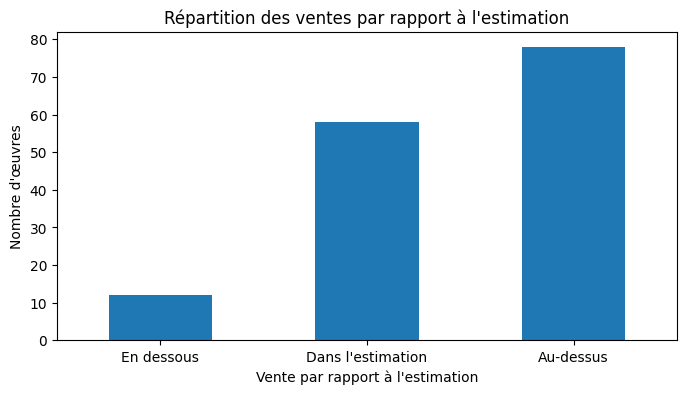

In [16]:
plt.figure(figsize=(8, 4))

df['vente_vs_estimation'].value_counts().sort_index().plot(kind='bar')

plt.xlabel("Vente par rapport à l'estimation")
plt.ylabel("Nombre d'œuvres")
plt.title("Répartition des ventes par rapport à l'estimation")

plt.xticks(
    ticks=[0, 1, 2],
    labels=["En dessous", "Dans l'estimation", "Au-dessus"],
    rotation=0
)

plt.show()

## 3.2 Graphiques bivariés

### 3.2.1 Scatter plot (variable continue contre continue)

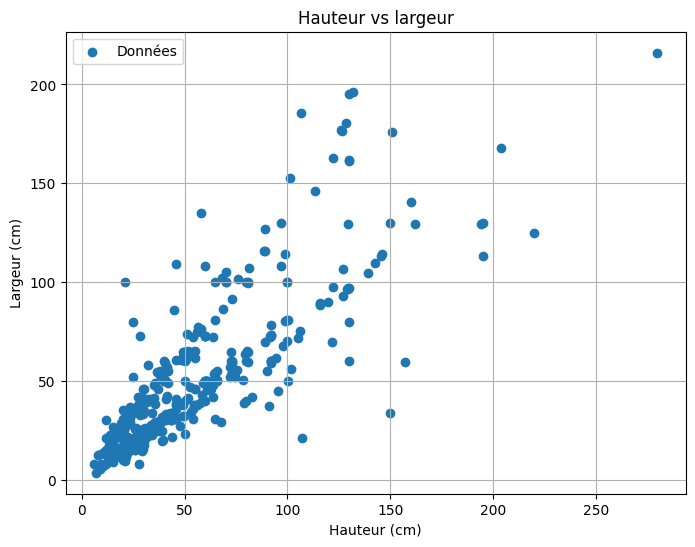

In [17]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["dim_hauteur_cm"],
    df["dim_largeur_cm"],
    label="Données"
)

plt.xlabel("Hauteur (cm)")
plt.ylabel("Largeur (cm)")
plt.title("Hauteur vs largeur")

plt.grid()
plt.legend()
plt.show()

### 3.2.2 Boxplot (variable catégorielle (ou ordinale) contre continue)

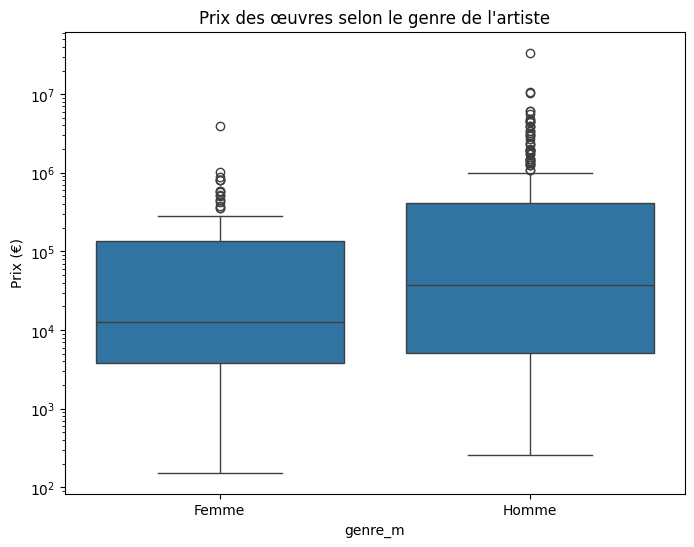

In [29]:
plt.figure(figsize=(8, 6))

sns.boxplot(data=df, x="genre_m", y="prix_euro")

plt.xticks([0, 1], ["Femme", "Homme"])

plt.ylabel("Prix (€)")
plt.title("Prix des œuvres selon le genre de l'artiste")

plt.yscale("log")

plt.show()

### 3.2.3 Countplot (variable catégorielle (ou ordinale) contre catégorielle (ou ordinale))

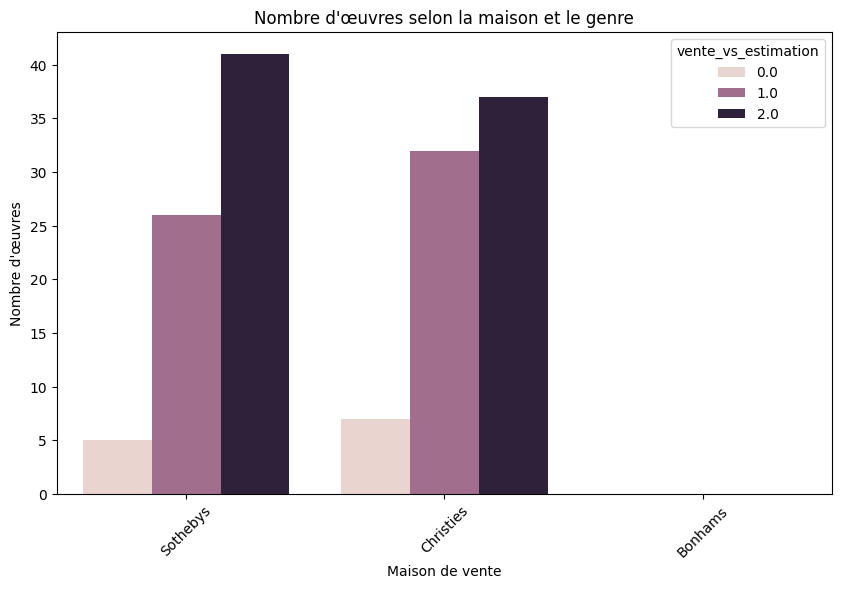

In [19]:
plt.figure(figsize=(10, 6))

sns.countplot(data=df, x="maison", hue="vente_vs_estimation")

plt.xlabel("Maison de vente")
plt.ylabel("Nombre d'œuvres")
plt.title("Nombre d'œuvres selon la maison et le genre")

plt.xticks(rotation=45)
plt.show()

À savoir : on peut aussi faire un graphique avec non pas les valeurs telles qu'elles sont mais les proportions pour mieux pouvoir comparer.

# 4. Travail individuel

Exercice final : choisissez deux variables. S'il faut les modifier ou en créer une nouvelle, faites-le. Ensuite, représentez les graphiquement avec la bonne représentation graphique. Enfin, faites un graphique bivarié.

Voici quelques ressources.

Les sites des bibliothèques :
- https://matplotlib.org/stable/plot_types/index.html
- https://seaborn.pydata.org/examples

Des sites plus synthétiques :
- https://python-graph-gallery.com/
- https://www.data-to-viz.com/